In [1]:
# PHY224H1F 2024 Practical Physics I
# Electron Charge-to-Mass Ratio (e/m) Experiment
# Oct 10, 2024
# Terry Chan # 1010156028
# Leon Qian #

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import uncertainties as unc
import uncertainties.unumpy as unp
from uncertainties import ufloat

In [3]:
# Import data
fixed_voltage = pd.read_csv('Fixed_voltage.csv')
fixed_current = pd.read_csv('Fixed_current.csv')

# Data processing
fixed_voltage.sort_values(by='Current (A)', inplace=True)
fixed_current.sort_values(by='Voltage (V)', inplace=True)
data = pd.concat((fixed_current, fixed_voltage), ignore_index=True)
data.reset_index(drop=True, inplace=True)
data = data[['Voltage (V)', 'Voltage std (V)', 'Current (A)', 'Current std (A)', 'Diameter (mm)']]

fixed_voltage_V = ufloat(fixed_voltage['Voltage (V)'][0], fixed_voltage['Voltage std (V)'][0])
fixed_current_A = ufloat(fixed_current['Current (A)'][0], fixed_current['Current std (A)'][0])
fixed_current_V = unp.uarray(fixed_current['Voltage (V)'], fixed_current['Voltage std (V)'])
fixed_voltage_A = unp.uarray(fixed_voltage['Current (A)'], fixed_voltage['Current std (A)'])
fixed_voltage_R = unp.uarray(fixed_voltage['Diameter (mm)'], 1) / 1000 / 2
fixed_current_R = unp.uarray(fixed_current['Diameter (mm)'], 1) / 1000 / 2

# Constants
MU_0 = 4 * np.pi * 10**-7  # T m/A; magnetic permeability of free space

R = 0.15  # m; radius of the Helmholtz coils
n = 130  # turns; number of turns of the Helmholtz coils

In [4]:
def B_coil(I):
    # I: current in the coil

    return (4/5)**(3/2) * MU_0 * n * I / R

def B_coil_correction_factor(rho):
    # rho: distance from the center of the coil
    
    # OK I didn't realize this thing goes below 0 so here's a fix
    f = 1 - (rho/R)**4 / (.6583 + .29 * (rho/R)**2)**2
    f = np.where(f < 0, 0, f)
    if f.shape == ():
        return f.item()
    return f

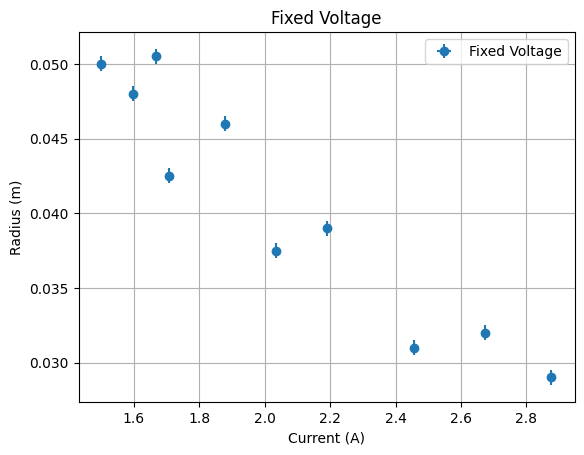

In [5]:
# Plot data for fixed voltage
fig, ax = plt.subplots()
ax.errorbar(unp.nominal_values(fixed_voltage_A), unp.nominal_values(fixed_voltage_R), xerr=unp.std_devs(fixed_voltage_A), yerr=unp.std_devs(fixed_voltage_R), fmt='o', label='Fixed Voltage')
ax.set_xlabel('Current (A)')
ax.set_ylabel('Radius (m)')
ax.set_title('Fixed Voltage')
ax.legend()
ax.grid()
plt.show()

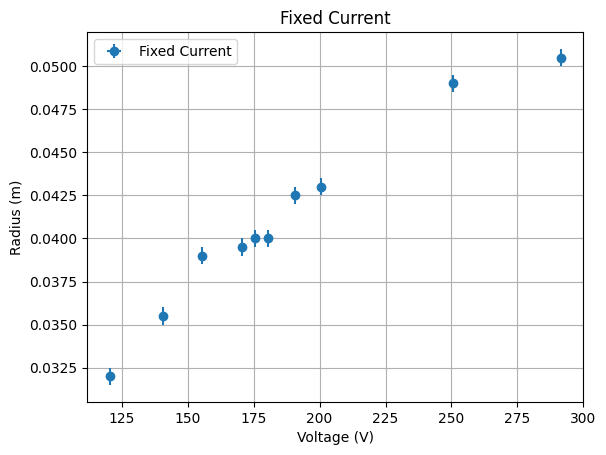

In [6]:
# Plot data for fixed current
fig, ax = plt.subplots()
ax.errorbar(unp.nominal_values(fixed_current_V), unp.nominal_values(fixed_current_R), xerr=unp.std_devs(fixed_current_V), yerr=unp.std_devs(fixed_current_R), fmt='o', label='Fixed Current')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Radius (m)')
ax.set_title('Fixed Current')
ax.legend()
ax.grid()
plt.show()

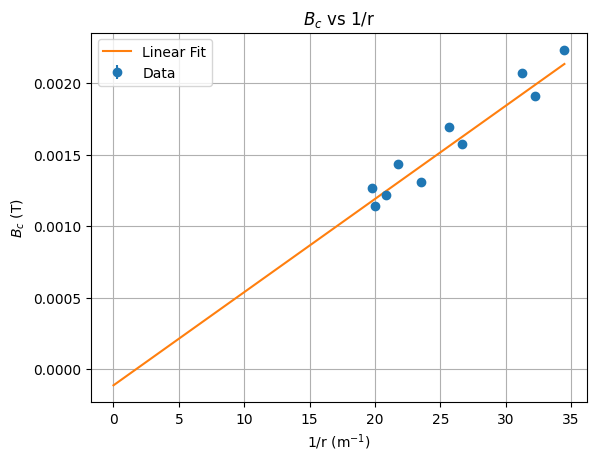

In [7]:
# Calculate the magnetic field strength for each data point
B_coil_strengths = B_coil_correction_factor(fixed_voltage_R) * B_coil(fixed_voltage_A)  

# Linear fit Bcoil against 1/r
def linear(x, a, b):
    return a * x + b

popt, pcov = curve_fit(linear, 1/unp.nominal_values(fixed_voltage_R), unp.nominal_values(B_coil_strengths), sigma=unp.std_devs(B_coil_strengths), absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
alpha = ufloat(popt[0], perr[0])
B_ext = ufloat(popt[1], perr[1])

# Plot Bcoil against 1/r
fig, ax = plt.subplots()
horizontal = np.linspace(0, 1/unp.nominal_values(fixed_voltage_R).min(), 100)
ax.errorbar(1/unp.nominal_values(fixed_voltage_R), unp.nominal_values(B_coil_strengths), yerr=unp.std_devs(B_coil_strengths), fmt='o', label='Data')
ax.plot(horizontal, linear(horizontal, *popt), label='Linear Fit')
ax.set_xlabel('1/r ($\\mathrm{m}^{-1}$)')
ax.set_ylabel('$B_c$ (T)')
ax.set_title('$B_c$ vs 1/r')
ax.legend()
ax.grid()
plt.savefig('B_c_vs_1_r.png')
plt.show()

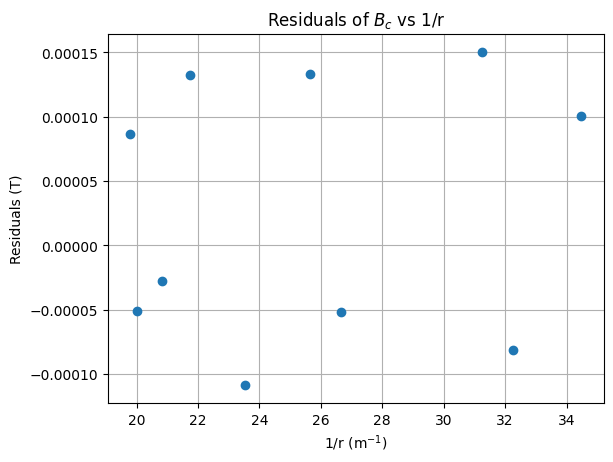

In [8]:
# Calculate and plot the residuals
residuals = B_coil_strengths - linear(1/unp.nominal_values(fixed_voltage_R), *popt)
fig, ax = plt.subplots()
ax.errorbar(1/unp.nominal_values(fixed_voltage_R), unp.nominal_values(residuals), yerr=unp.std_devs(residuals), fmt='o')
ax.set_xlabel('1/r ($\\mathrm{m}^{-1}$)')
ax.set_ylabel('Residuals (T)')
ax.set_title('Residuals of $B_c$ vs 1/r')
ax.grid()
plt.savefig('Residuals_B_c_vs_1_r.png')
plt.show()

In [9]:
# Geomagnetic field data at the lab at the time of the experiment
# Source: https://www.ngdc.noaa.gov/geomag/calculators/magcalc.shtml#igrfwmm
geomagnetic_data = pd.read_csv('Earth Magnetic Field Data.csv', comment='#', header=None).values

B_earth_north = ufloat(geomagnetic_data[2][5], geomagnetic_data[1][5]) / 1e9  # T
B_earth_horiz = ufloat(geomagnetic_data[2][3], geomagnetic_data[1][3]) / 1e9  # T 
B_earth_total = ufloat(geomagnetic_data[2][4], geomagnetic_data[1][4]) / 1e9  # T

# Compare B_coil, B_ext, and B_earth_north
B_coil_strengths_mean = B_coil_strengths.mean()
print(f'B_coil_mean ≈ {B_coil_strengths_mean:.2ueP} T')
print(f'B_ext = {B_ext:.2ueP} T')
print(f'B_earth_north = {B_earth_north:.2ueP} T')
print(f'B_earth_horiz = {B_earth_horiz:.2ueP} T')
print(f'B_earth_total = {B_earth_total:.2ueP} T')
print()

print(f'B_coil_mean / B_ext = {B_coil_strengths_mean / B_ext:.2uP}')
print(f'B_ext / B_earth_north = {B_ext / B_earth_north:.2uP}')
print(f'B_coil_mean / B_earth_north = {B_coil_strengths_mean / B_earth_north:.2uP}')
print(f'B_coil_mean / B_earth_horiz = {B_coil_strengths_mean / B_earth_horiz:.2uP}')
print(f'B_coil_mean / B_earth_total = {B_coil_strengths_mean / B_earth_total:.2uP}')

B_coil_mean ≈ (1.58454±0.00039)×10⁻³ T
B_ext = (-1.138±0.020)×10⁻⁴ T
B_earth_north = (1.876±0.013)×10⁻⁵ T
B_earth_horiz = (1.906±0.013)×10⁻⁵ T
B_earth_total = (5.315±0.015)×10⁻⁵ T

B_coil_mean / B_ext = -13.93±0.24
B_ext / B_earth_north = -6.07±0.11
B_coil_mean / B_earth_north = 84.47±0.59
B_coil_mean / B_earth_horiz = 83.14±0.56
B_coil_mean / B_earth_total = 29.812±0.082


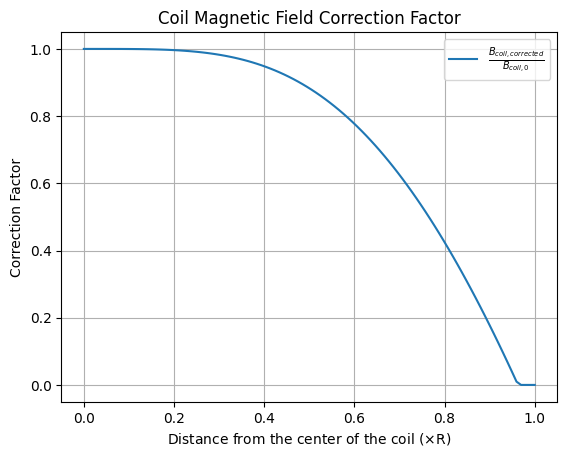

In [10]:
# The result is quite unexpected
# The external magnetic field is much stronger than the geomagnetic field
# It also has the opposite direction
# This suggests that the external magnetic field is not the geomagnetic field
# What could it be?
#
# It could be the case that the correction of the coil magnetic field is not accurate
# since the correction is only accurate for .2R < rho < .5R

# Plot the correction factor
fig, ax = plt.subplots()
rho = np.linspace(0, R, 100)
ax.plot(rho/R, B_coil_correction_factor(rho),label='$\\frac{B_{coil, corrected}}{B_{coil, 0}}$')
ax.set_xlabel('Distance from the center of the coil ($\\times$R)')
ax.set_ylabel('Correction Factor')
ax.set_title('Coil Magnetic Field Correction Factor')
ax.legend()
ax.grid()
plt.savefig('Coil_Magnetic_Field_Correction_Factor.png')
plt.show()

# This thing goes below 0???
## Fixed so it gets clamped to 0

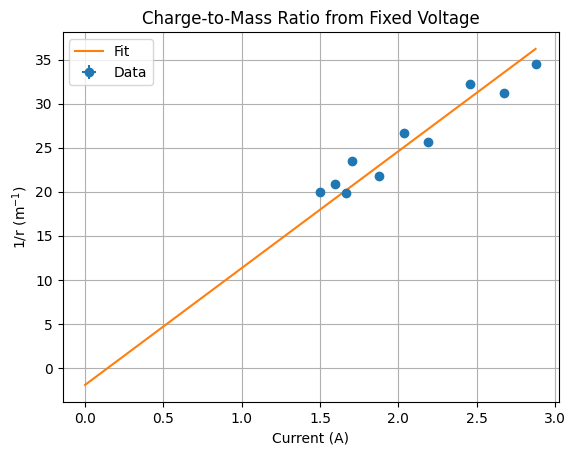

C:\Users\ihatemmorpg\AppData\Local\Temp\ipykernel_24512\3835151297.py:6: RuntimeWarning: divide by zero encountered in divide
  return e_m**(1/2) * k * (I + I_0.nominal_value / 2**(1/2)) / V**(1/2)


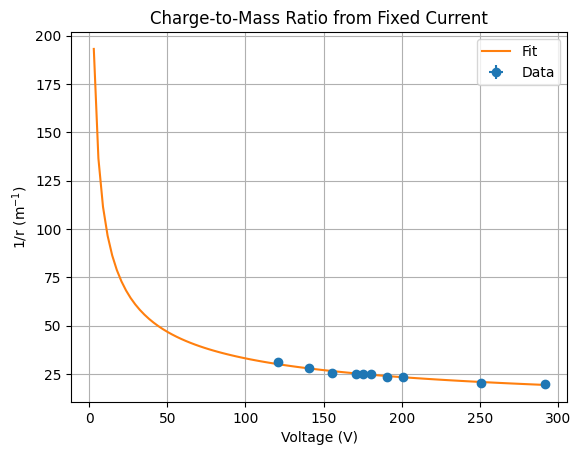

In [11]:
# Calculate the charge-to-mass ratio of the electron by fitting the data
k = 2**(-1/2) * (4/5)**(3/2) * MU_0 * n / R
I_0 = B_ext / k

def model(I, V, e_m):
    return e_m**(1/2) * k * (I + I_0.nominal_value / 2**(1/2)) / V**(1/2)

const_V_model = lambda I, e_m: model(I, unp.nominal_values(fixed_voltage_V), e_m)
const_I_model = lambda V, e_m: model(unp.nominal_values(fixed_current_A), V, e_m)

popt_V, pcov_V = curve_fit(const_V_model, unp.nominal_values(fixed_voltage_A), 1/unp.nominal_values(fixed_voltage_R), sigma=unp.std_devs(fixed_voltage_R), absolute_sigma=True)
perr_V = np.sqrt(np.diag(pcov_V))
e_m_V = ufloat(popt_V[0], perr_V[0])

popt_I, pcov_I = curve_fit(const_I_model, unp.nominal_values(fixed_current_V), 1/unp.nominal_values(fixed_current_R), sigma=unp.std_devs(fixed_current_R), absolute_sigma=True)
perr_I = np.sqrt(np.diag(pcov_I))
e_m_I = ufloat(popt_I[0], perr_I[0])

# Plot the data and the fits
fig, ax = plt.subplots()
horizontal = np.linspace(0, unp.nominal_values(fixed_voltage_A).max(), 100)
ax.errorbar(unp.nominal_values(fixed_voltage_A), 1/unp.nominal_values(fixed_voltage_R), xerr=unp.std_devs(fixed_voltage_A), yerr=unp.std_devs(fixed_voltage_R), fmt='o', label='Data')
ax.plot(horizontal, const_V_model(horizontal, *popt_V), label='Fit')
ax.set_xlabel('Current (A)')
ax.set_ylabel('1/r ($\\mathrm{m}^{-1}$)')
ax.set_title('Charge-to-Mass Ratio from Fixed Voltage')
ax.legend()
ax.grid()
plt.savefig('Charge_to_Mass_Ratio_from_Fixed_Voltage.png')
plt.show()

fig, ax = plt.subplots()
horizontal = np.linspace(0, unp.nominal_values(fixed_current_V).max(), 100)
ax.errorbar(unp.nominal_values(fixed_current_V), 1/unp.nominal_values(fixed_current_R), xerr=unp.std_devs(fixed_current_V), yerr=unp.std_devs(fixed_current_R), fmt='o', label='Data')
ax.plot(horizontal, const_I_model(horizontal, *popt_I), label='Fit')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('1/r ($\\mathrm{m}^{-1}$)')
ax.set_title('Charge-to-Mass Ratio from Fixed Current')
ax.legend()
ax.grid()
plt.savefig('Charge_to_Mass_Ratio_from_Fixed_Current.png')
plt.show()

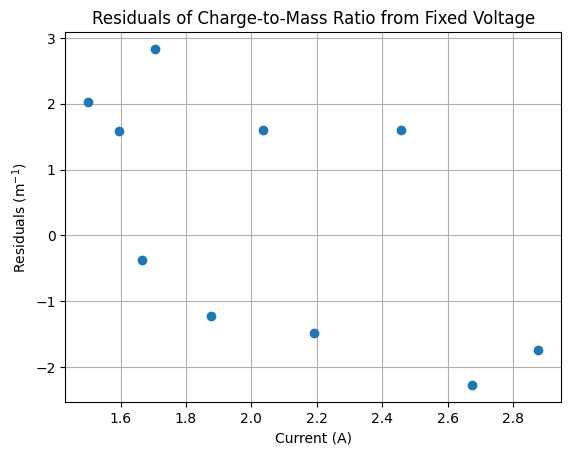

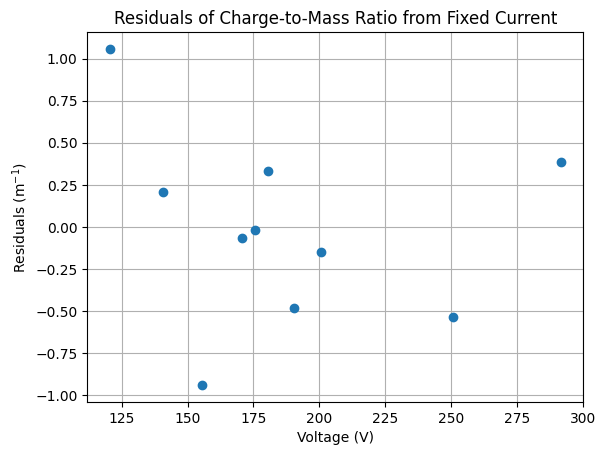

e/m from fixed voltage = (2.128636±0.000026)×10¹¹ C/kg
e/m from fixed current = (2.465366±0.000031)×10¹¹ C/kg
e/m from fixed voltage / e/m from fixed current = 0.863416±0.000015
Actual value of e/m = (1.75882000838±0.00000000055)×10¹¹ C/kg


In [12]:
# Calculate and plot the residuals
residuals_V = 1/unp.nominal_values(fixed_voltage_R) - const_V_model(unp.nominal_values(fixed_voltage_A), *popt_V)
fig, ax = plt.subplots()
ax.errorbar(unp.nominal_values(fixed_voltage_A), unp.nominal_values(residuals_V), xerr=unp.std_devs(fixed_voltage_A), yerr=unp.std_devs(residuals_V), fmt='o')
ax.set_xlabel('Current (A)')
ax.set_ylabel('Residuals ($\\mathrm{m}^{-1}$)')
ax.set_title('Residuals of Charge-to-Mass Ratio from Fixed Voltage')
ax.grid()
plt.savefig('Residuals_Charge_to_Mass_Ratio_from_Fixed_Voltage.png')
plt.show()

residuals_I = 1/unp.nominal_values(fixed_current_R) - const_I_model(unp.nominal_values(fixed_current_V), *popt_I)
fig, ax = plt.subplots()
ax.errorbar(unp.nominal_values(fixed_current_V), unp.nominal_values(residuals_I), xerr=unp.std_devs(fixed_current_V), yerr=unp.std_devs(residuals_I), fmt='o')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Residuals ($\\mathrm{m}^{-1}$)')
ax.set_title('Residuals of Charge-to-Mass Ratio from Fixed Current')
ax.grid()
plt.savefig('Residuals_Charge_to_Mass_Ratio_from_Fixed_Current.png')
plt.show()

# Compare the two results
print(f'e/m from fixed voltage = {e_m_V:.2ueP} C/kg')
print(f'e/m from fixed current = {e_m_I:.2ueP} C/kg')
print(f'e/m from fixed voltage / e/m from fixed current = {e_m_V / e_m_I:.2uP}')
print(f'Actual value of e/m = {unc.ufloat_fromstr('1.75882000838(55)e11'):.2ueP} C/kg')